In [4]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [13]:


df = pd.read_csv("auto-mpg.csv")

print("First Five Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

df = df.drop('car name', axis=1)

print("Columns after removing car name:")
print(df.columns)

First Five Rows:
    mpg  cylinders  displacement horsepower  weight  acceleration  model year  \
0  18.0          8         307.0        130    3504          12.0          70   
1  15.0          8         350.0        165    3693          11.5          70   
2  18.0          8         318.0        150    3436          11.0          70   
3  16.0          8         304.0        150    3433          12.0          70   
4  17.0          8         302.0        140    3449          10.5          70   

   origin                   car name  
0       1  chevrolet chevelle malibu  
1       1          buick skylark 320  
2       1         plymouth satellite  
3       1              amc rebel sst  
4       1                ford torino  

Dataset Shape:
(398, 9)

Missing Values:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64
Columns after removing car name:
Index(['mpg'

In [22]:
print("Missing Values Before Handling:")
print(df.isnull().sum())

# Convert horsepower to numeric
df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')

# Fill missing values, if any
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())

# Check dataset
print(df.head())
print("\nMissing Values:")
print(df.isnull().sum())

Missing Values Before Handling:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
dtype: int64
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model year  origin  
0          70       1  
1          70       1  
2          70       1  
3          70       1  
4          70       1  

Missing Values:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
dtype: int64


In [23]:
X = df.drop('mpg', axis=1)

y = df['mpg']

print("Input Features:")
print(X.columns)

print("\nTarget Variable:")
print(y.head())

Input Features:
Index(['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration',
       'model year', 'origin'],
      dtype='object')

Target Variable:
0    18.0
1    15.0
2    18.0
3    16.0
4    17.0
Name: mpg, dtype: float64


In [24]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (318, 7)
Testing Data: (80, 7)


In [25]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed")

Feature Scaling Completed


In [26]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

print("Model Trained Successfully!")

Model Trained Successfully!


In [27]:
y_pred = model.predict(X_test_scaled)

print("Actual MPG:")
print(y_test.head().values)

print("\nPredicted MPG:")
print(y_pred[:5])

Actual MPG:
[33. 28. 19. 13. 14.]

Predicted MPG:
[32.88140046 29.55780381 21.36955005 16.79734409 12.4982001 ]


In [28]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 2.2553632612835637
Mean Squared Error: 8.197746885824964
Root Mean Squared Error: 2.8631707748272657
R2 Score: 0.8475304239212407


In [29]:
correlation = df.corr(numeric_only=True)

print(correlation['mpg'].sort_values(ascending=False))

mpg             1.000000
model year      0.579267
origin          0.563450
acceleration    0.420289
horsepower     -0.773453
cylinders      -0.775396
displacement   -0.804203
weight         -0.831741
Name: mpg, dtype: float64


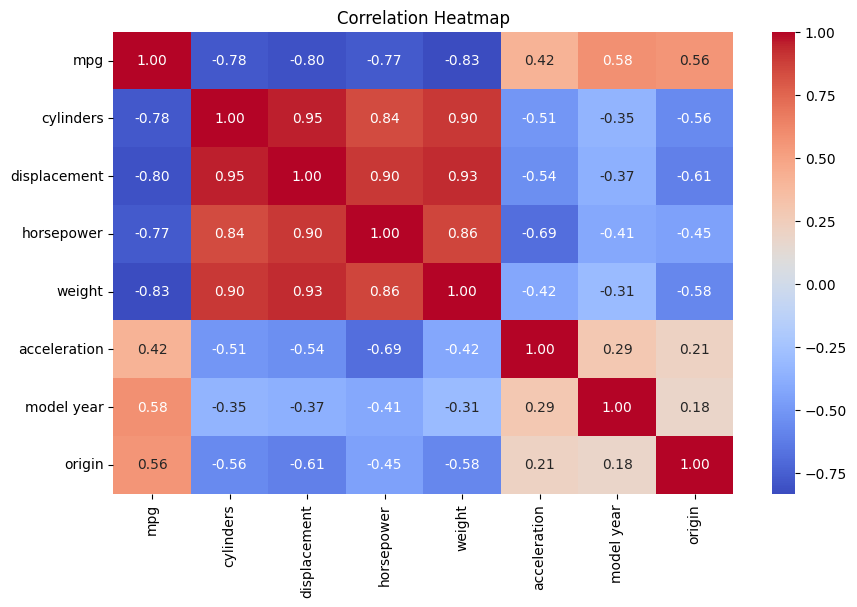

In [30]:
plt.figure(figsize=(10, 6))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Heatmap")

plt.show()

In [31]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

print(importance.sort_values(by='Coefficient', ascending=False))

        Feature  Coefficient
5    model year     2.859873
1  displacement     1.462161
6        origin     1.072150
4  acceleration     0.189747
0     cylinders    -0.263773
2    horsepower    -0.488278
3        weight    -5.662199


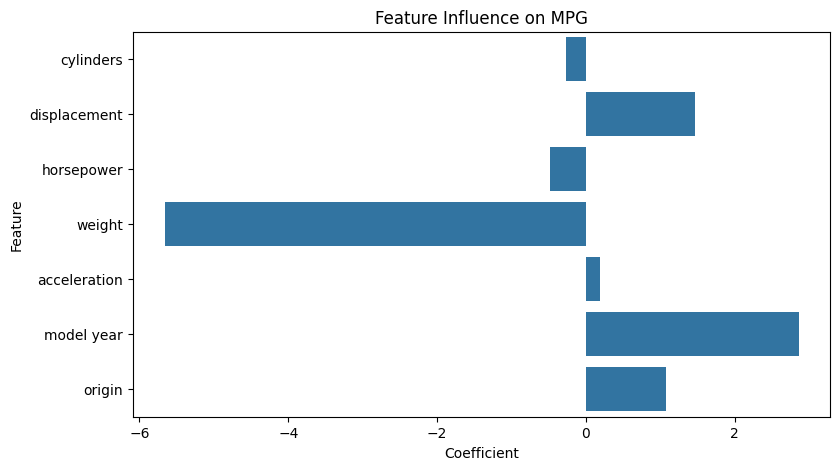

In [32]:
plt.figure(figsize=(9, 5))

sns.barplot(data=importance, x='Coefficient', y='Feature')

plt.title("Feature Influence on MPG")

plt.show()

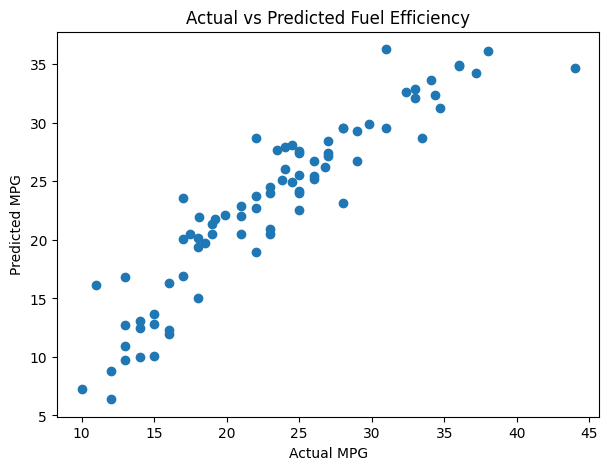

In [35]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")

plt.title("Actual vs Predicted Fuel Efficiency")

plt.show()

In [34]:
new_car = pd.DataFrame({
    'cylinders': [4],
    'displacement': [120],
    'horsepower': [90],
    'weight': [2500],
    'acceleration': [15],
    'model year': [80],
    'origin': [3]
})

new_car_scaled = scaler.transform(new_car)

prediction = model.predict(new_car_scaled)

print("Predicted Fuel Efficiency:", prediction[0], "MPG")

Predicted Fuel Efficiency: 31.06444947625361 MPG
